# Arbeitspaket (AP) 8: Datenbeschaffung, Datenaufbereitung & explorative Datenanalyse

### Persönliche Angaben (bitte ergänzen) und Prüfungsregeln

<table>
  <tr><td>Vorname:</td><td></td></tr>
  <tr><td>Nachname:</td><td></td></tr>
  <tr><td>Immatrikulationsnummer:</td><td></td></tr>
  <tr><td>Modul:</td><td>Data Science</td></tr>
  <tr><td>Prüfungsdatum / Raum / Zeit:</td><td>[TT.MM.2026] / Raum: [anpassen] / [hh:mm – hh:mm]</td></tr>
  <tr><td>Erlaubte Hilfsmittel:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Nicht erlaubt:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Technische Probleme:</td><td>Wenden Sie sich bei technischen Problemen umgehend an die Prüfungsaufsicht.</td></tr>
</table>

## Bewertungskriterien

**(max. erreichbare Punkte: 40)**

<table>
  <thead>
    <tr><th>Teil</th><th>Thema</th><th>Aufgaben</th><th>Punkte</th></tr>
  </thead>
  <tbody>
    <tr><td>A</td><td>Konzeptfragen: Datenaufbereitung &amp; explorative Datenanalyse</td><td>A1–A3</td><td>12</td></tr>
    <tr><td>B</td><td>Fehleranalyse Python-Code (Wohnungsinserate)</td><td>B1–B2</td><td>16</td></tr>
    <tr><td>C</td><td>Python-Code schreiben: Web Scraping, JSON, Datenaufbereitung &amp; EDA</td><td>C1–C3</td><td>12</td></tr>
    <tr><td><b>Total</b></td><td></td><td><b>8 Aufgaben</b></td><td><b>40</b></td></tr>
  </tbody>
</table>

### Bewertungsschema

Jede Aufgabe wird für sich und **als Ganzes** bewertet. Ihre Punktzahl steht in der Überschrift.

<table>
  <thead>
    <tr><th>Kategorie</th><th>Beschreibung</th><th>Bewertung</th><th>4 Pkt</th><th>8 Pkt</th></tr>
  </thead>
  <tbody>
    <tr><td>Korrekt</td><td>Vollständig und fachlich einwandfrei: Antwort bzw. Begründung korrekt und nachvollziehbar; bei Code-Aufgaben liefert der Python-Code das richtige Ergebnis</td><td>100%</td><td>4</td><td>8</td></tr>
    <tr><td>Minimale Mängel</td><td>Kleine Fehler (z.B. falsche Sortierung, fehlende Rundung, fehlende Achsenbeschriftung) oder Begründung ungenau bzw. unvollständig</td><td>75%</td><td>3</td><td>6</td></tr>
    <tr><td>Mittlere Mängel</td><td>Grössere Fehler (z.B. fehlende Spalten, falsche Filterung) oder Begründung fehlt bzw. ist fachlich falsch</td><td>50%</td><td>2</td><td>4</td></tr>
    <tr><td>Gravierende Mängel</td><td>Problem bzw. Ansatz erkennbar, aber Lösung oder Schlussfolgerung im Kern falsch (z.B. Problem richtig benannt, aber falsch behoben; im Code: ungeeigneter Lösungsweg wie falscher Join-Typ, falsche Tabelle oder falsche Datei)</td><td>25%</td><td>1</td><td>2</td></tr>
    <tr><td>Nicht lauffähig / nicht sinnvoll</td><td>Antwort fehlt, Code nicht lauffähig (z.B. Syntaxfehler) oder kein Bezug zur Aufgabe</td><td>0%</td><td>0</td><td>0</td></tr>
  </tbody>
</table>

Treffen mehrere Mängel zusammen, zählt der schwerste. Alternative, fachlich korrekte Lösungswege werden ebenfalls als korrekt gewertet.

## Hinweise zu den Daten

Alle Daten stammen von der **fiktiven** Schweizer Immobilienplattform «WohnMarkt» und liegen **lokal** im gleichen Verzeichnis wie dieses Notebook. Für die Prüfung ist **kein Internetzugriff** auf Websites oder APIs nötig.

<table>
  <thead>
    <tr><th>Datei</th><th>Format</th><th>Inhalt</th></tr>
  </thead>
  <tbody>
    <tr><td><code>html/listings_page_1.html</code> … <code>listings_page_3.html</code></td><td>HTML</td><td>Gespeicherte Ergebnisseiten mit Mietwohnungs-Inseraten (3 Seiten mit Paginierung)</td></tr>
    <tr><td><code>html/listing_detail.html</code></td><td>HTML</td><td>Gespeicherte Detailseite eines Inserats (Tabellen «Kosten» und «Objektdaten»)</td></tr>
    <tr><td><code>municipalities.json</code></td><td>JSON</td><td>Gespeicherte Antwort der Gemeinde-API: Metadaten und Liste der Gemeinden (verschachtelt)</td></tr>
    <tr><td><code>apartments_clean.csv</code></td><td>CSV</td><td>Aufbereitete Inserate: Formate vereinheitlicht, Duplikate entfernt — <b>inhaltlich nicht geprüft</b></td></tr>
  </tbody>
</table>

Die Spaltenbeschreibungen finden Sie im Sheet **«Description»**, die Datenquellen im Sheet **«Data Sources»** der beiliegenden Datei `apartment_data.xlsx`. Alle Mieten sind **Nettomieten in CHF pro Monat**. Die HTML-Dateien können Sie zur Ansicht auch im Browser oder als Text im Editor öffnen.

**Antworten auf Konzeptfragen** und **Begründungen** tragen Sie bitte direkt in die vorgesehenen Markdown-Zellen ein.

## Setup (wird nicht bewertet)

In [1]:
# Libraries
import os
import re
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Get current working directory
print(os.getcwd())

/home/claude/out/DS_HS2026_LNW_I_Examples/AP08


### Ergebnisseiten scrapen → `df_raw`

Der folgende Code liest die drei gespeicherten Ergebnisseiten mit BeautifulSoup ein (analog zur Übung `skipass_data.ipynb`). Jedes Inserat (`<article class="listing">`) wird zu einer Zeile im Data Frame `df_raw`. Die Werte werden **als Text** übernommen (Spalten mit Endung `_raw`) und noch nicht bereinigt.

In [2]:
# Initialize list for the extracted rows
rows = []

# Loop over the three listing pages
for page in [1, 2, 3]:

    # Read html from file
    with open(f'html/listings_page_{page}.html', 'r', encoding='utf-8') as file:
        html_content = file.read()

    # Parse the HTML content
    soup = BeautifulSoup(html_content, 'html.parser')

    # Locate the listings and extract values
    for listing in soup.select('article.listing'):
        row_data = [listing['data-listing-id'],
                    listing.select('span.rooms')[0].get_text().replace('\xa0', '').strip(),
                    listing.select('span.area')[0].get_text().replace('\xa0', '').strip(),
                    listing.select('span.floor')[0].get_text().replace('\xa0', '').strip(),
                    listing.select('span.zip')[0].get_text().strip(),
                    listing.select('span.town')[0].get_text().strip(),
                    listing.select('span.rent')[0].get_text().replace('\xa0', '').strip(),
                    listing.select('span.provider')[0].get_text().replace('Anbieter:', '').strip()]
        rows.append(row_data)

# Create a DataFrame
df_raw = pd.DataFrame(rows, columns=['listing_id', 'rooms_raw', 'area_raw', 'floor', 'zip', 'town',
                                     'rent_raw', 'provider'])

# Show dimensions and first rows
print('Number of rows and columns:', df_raw.shape)
df_raw.head()

Number of rows and columns: (188, 8)


,listing_id,rooms_raw,area_raw,floor,zip,town,rent_raw,provider
0,WM-20001,5.5Zimmer,122m²,3. OG,8400,Winterthur,CHF 2'570.– / Monat,Agentur
1,WM-20002,3.5Zimmer,k.A.,1. OG,8001,Zürich,CHF 3'300.– / Monat,Privat
2,WM-20003,3.5Zimmer,89m²,2. OG,2502,Biel/Bienne,CHF 18'600.– / Monat,Privat
3,WM-20004,2.5Zimmer,68m²,1. OG,3011,Bern,CHF 1'550.– / Monat,Agentur
4,WM-20005,3.5Zimmer,83m²,1. OG,6003,Luzern,CHF 2'100.– / Monat,Privat


### Aufbereitete Inserate laden → `df_clean`

In [3]:
# Import data from csv to pandas dataframe named 'df_clean'
df_clean = pd.read_csv('apartments_clean.csv')

# Show dimensions and first rows
print('Number of rows and columns:', df_clean.shape)
df_clean.head()

Number of rows and columns: (180, 9)


,listing_id,title,provider,zip,town,rooms,area_m2,floor,rent_chf
0,WM-20001,Renovierte 5.5-Zimmer-Wohnung mit Seesicht,Agentur,8400,Winterthur,5.5,122.0,3. OG,2570.0
1,WM-20002,Moderne 3.5-Zimmer-Wohnung mit Seesicht,Privat,8001,Zürich,3.5,NaN,1. OG,3300.0
2,WM-20003,Renovierte 3.5-Zimmer-Wohnung mit Lift,Privat,2502,Biel/Bienne,3.5,89.0,2. OG,18600.0
3,WM-20004,Gemütliche 2.5-Zimmer-Wohnung mit Gartensitzplatz,Agentur,3011,Bern,2.5,68.0,1. OG,1550.0
4,WM-20005,Renovierte 3.5-Zimmer-Wohnung mit Balkon,Privat,6003,Luzern,3.5,83.0,1. OG,2100.0


> **Hinweis:** Alle Aufgaben sind voneinander unabhängig. Verändern Sie `df_raw` und `df_clean` bitte nicht direkt, sondern arbeiten Sie in jeder Aufgabe mit einem eigenen Data Frame (z.B. `df_B1`, `df_C2`).

---

<div style="background-color:#2E4057; color:white; padding:16px 24px; border-radius:6px; font-size:18px; margin-top:8px;">
&#9654;&nbsp; <strong>Ab hier beginnt die bewertete Prüfung — 40 Punkte</strong><br>
<span style="font-size:15px; font-weight:normal;">Tragen Sie Ihre Antworten direkt in die vorgesehenen Zellen ein und führen Sie alle Code-Zellen aus.</span>
</div>

---
## Teil A – Konzeptfragen (12 Punkte)

*Antworten ohne Bezug zu den Inseraten von «WohnMarkt» werden nicht gewertet.*

### A1 (4 Punkte)

Bei 21 der 180 Inserate fehlt die Wohnfläche («k.A.»). Eine Kreuztabelle zeigt:

```
pd.crosstab(df_clean['provider'], df_clean['area_m2'].isnull())

area_m2   False  True
provider
Agentur     130     3
Privat       29    18
```

a) Um welchen Mechanismus fehlender Werte handelt es sich am ehesten (MCAR, MAR oder MNAR)? Begründen Sie mit der Tabelle.

b) Ein Analyst entfernt die 21 Inserate und berichtet die durchschnittliche Miete pro m² «des Marktes». Welches Problem entsteht dadurch, und wie könnte man die fehlenden Werte besser behandeln?

**Ihre Antwort:**

a) **MAR (Missing at Random):** Ob die Wohnfläche fehlt, hängt von einer **anderen, beobachteten** Variable ab — dem Anbieter: Bei privaten Inseraten fehlt sie in 18 von 47 Fällen (38 %), bei Agenturen nur in 3 von 133 (2 %). MCAR ist es nicht, weil das Fehlen nicht zufällig über alle Inserate verteilt ist. (MNAR läge vor, wenn das Fehlen von der Wohnfläche selbst abhinge, z.B. wenn gerade kleine Wohnungen keine Fläche angeben — das lässt sich mit den Daten nicht prüfen.)

b) Nach dem Entfernen sind **private Inserate untervertreten** (29 statt 47). Unterscheiden sich private Angebote systematisch (z.B. günstigere Altbauwohnungen), ist die berichtete Miete pro m² **verzerrt** und nicht mehr repräsentativ für den Markt. Besser: fehlende Flächen **imputieren**, z.B. mit dem Median der Wohnfläche von Inseraten mit gleicher Zimmerzahl (Fläche hängt stark von `rooms` ab), oder die Kennzahl getrennt nach Anbieter ausweisen und die Einschränkung offenlegen.

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 8–11 (Missing Values: Imputation, Removal, MCAR/MAR/MNAR: «If removed, the result will be biased»); Folien Woche 5, S. 21–22 (Kontingenztabelle).*

### A2 (4 Punkte)

Für die Monatsmiete `rent_chf` liefert pandas:

```
df_clean['rent_chf'].describe()          df_clean['rent_chf'].skew()
count      173.00                         7.19
mean      2339.65
std       2458.32
min        760.00
25%       1550.00
50%       2020.00
75%       2500.00
max      25320.00
```

a) Berechnen Sie die obere Grenze, ab der ein Boxplot einen Wert als **Ausreisser** darstellt (1.5 × IQR-Regel). Geben Sie den Rechenweg an.

b) Oberhalb dieser Grenze liegen 5 Inserate:

```
listing_id   town          rooms  area_m2  rent_chf
WM-20003     Biel/Bienne     3.5     89.0   18600.0
WM-20016     St. Gallen      5.5    133.0   25320.0
WM-20021     Biel/Bienne     2.5     70.0   14400.0
WM-20035     Zürich          5.5    137.0    4300.0
WM-20129     Zürich          5.5    137.0    5160.0
```

Welche davon würden Sie als **Erfassungsfehler** einstufen, welche nicht? Begründen Sie und schlagen Sie eine Behandlung vor.

**Ihre Antwort:**

a) IQR = Q3 − Q1 = 2500 − 1550 = 950; obere Grenze = Q3 + 1.5 · IQR = 2500 + 1.5 · 950 = **CHF 3'925**.

b) **Erfassungsfehler:** WM-20003, WM-20016 und WM-20021. Ihre Miete pro m² liegt bei rund CHF 190–210 pro Monat — ein Vielfaches des Üblichen (sonst höchstens rund CHF 41/m²), und das in Biel und St. Gallen, nicht in Zürich. Geteilt durch 12 ergeben sich plausible Monatsmieten (CHF 1'550, 2'110 bzw. 1'200): Offensichtlich wurde die **Jahresmiete** erfasst. Behandlung: durch 12 teilen (die Ursache ist bekannt) oder — falls unsicher — entfernen und dokumentieren.

**Keine Fehler:** die beiden 5.5-Zimmer-Wohnungen in Zürich mit 137 m² (CHF 31–38/m²). Sie sind zwar statistische **Ausreisser**, aber plausibel (grosse Wohnungen am teuersten Standort) und sollten deshalb **nicht** entfernt werden. Ausreisser sind nicht automatisch Fehler.

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil II, S. 13 (Outliers & Measurement Errors: «should be examined and only removed if they are errors»); Folien Woche 5, S. 15–17 (Quantile, Interquartilsabstand), S. 18–19 (Schiefe) und S. 29–30 (Box plot).*

### A3 (4 Punkte)

Für ein Machine-Learning-Modell zur Mietpreisschätzung soll die Variable `town` (8 Orte) als Feature verwendet werden. Ein Kollege codiert sie so:

```python
codes = {'Zürich': 1, 'Winterthur': 2, 'Bern': 3, 'Basel': 4, 'Luzern': 5,
         'St. Gallen': 6, 'Biel/Bienne': 7, 'Schaffhausen': 8}
df['town_code'] = df['town'].map(codes)
```

a) Welches Skalenniveau hat `town`, und warum ist diese Codierung problematisch?

b) Welche Alternative schlagen Sie vor? Wie viele neue Spalten entstehen dabei?

**Ihre Antwort:**

a) `town` ist **nominal** — die Orte haben keine natürliche Reihenfolge. Die Codierung 1–8 unterstellt aber eine **Rangfolge und gleiche Abstände**: Ein Modell (z.B. eine lineare Regression) würde annehmen, dass Schaffhausen (8) «achtmal so viel Ort» ist wie Zürich (1) und der Effekt von Zürich → Winterthur gleich gross ist wie von Biel → Schaffhausen. Das ist inhaltlich sinnlos und verzerrt die Schätzung.

b) **One-Hot-Encoding** (z.B. `pd.get_dummies(df['town'])` oder `OneHotEncoder`): Für jeden Ort entsteht eine eigene 0/1-Spalte — **8 Spalten**. Für eine lineare Regression mit Konstante lässt man eine Kategorie als Referenz weg (`drop_first=True`) → **7 Spalten**; sonst sind die Spalten perfekt kollinear (Dummy-Falle).

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bewertung: Sowohl 8 als auch 7 Spalten (mit Begründung Referenzkategorie) gelten als korrekt.*
>
> *Bezug: Folien Woche 4 Teil II, S. 6–7 (Scale of Measure – choice of statistical method / machine learning model) und S. 28–29 (One-Hot Encoding: «No Ordinal Relationships: Prevents the model …»).*

---
## Teil B – Fehleranalyse Python-Code (16 Punkte)

*Jeder Code läuft fehlerfrei durch, liefert aber ein falsches oder irreführendes Ergebnis. Die tatsächlichen Ergebnisse sind angegeben.*

### B1 (8 Punkte)

**Ziel:** Kennzahlen aus den gescrapten Rohdaten `df_raw`: Anzahl Inserate, Anzahl Inserate ohne Mietangabe und Median-Miete in CHF.

```python
# Select columns for the analysis
df_B1 = df_raw[['listing_id', 'town', 'rooms_raw', 'rent_raw']]

# Extract numerical values from rent_raw
rent = []
for i in df_B1['rent_raw']:
    d1 = re.findall(r"\d+", i)
    try:
        d2 = int(''.join(d1))
    except:
        d2 = 0
    rent.append(d2)

# Save as new variable in the pandas data frame
df_B1['rent_chf'] = pd.Series(rent, dtype="Int64")

# Show key figures
print('Anzahl Inserate:          ', df_B1.shape[0])
print('Anzahl ohne Mietangabe:   ', df_B1['rent_chf'].isnull().sum())
print('Median-Miete (CHF):       ', df_B1['rent_chf'].median())
```

Tatsächliches Ergebnis:

```
Anzahl Inserate:           188
Anzahl ohne Mietangabe:    0
Median-Miete (CHF):        1965.0
```

Die Plattform gibt auf jeder Seite an, dass sie **180 Inserate** führt. Beispiele für Werte in `rent_raw`: `CHF 2'150.– / Monat`, `Miete auf Anfrage`.

**Aufgabe:** Schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben), sodass die Kennzahlen stimmen. Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

1. **Duplikate entfernen:** Die Ergebnisseiten überlappen sich (Paginierung) — die letzten Inserate einer Seite erscheinen auf der nächsten Seite noch einmal. `drop_duplicates()` entfernt die 8 identischen Zeilen (188 → 180), `reset_index(drop=True)` nummeriert den Index neu. Ohne `reset_index` würde `pd.Series(rent)` (Index 0–179) nicht mehr zum Index des Data Frames passen.
2. **Fehlende Werte als `None` statt `0`:** Bei «Miete auf Anfrage» findet `re.findall()` keine Ziffern; `int('')` löst einen Fehler aus und der `except`-Zweig setzt `0`. Eine Miete von CHF 0 ist aber ein **falscher Wert**, kein fehlender: Die 7 Inserate werden nicht als fehlend erkannt und ziehen Median (und Mittelwert) nach unten. Mit `d2 = None` werden sie korrekt als fehlend (`<NA>`) gespeichert und von `median()` ignoriert.

Ergebnis: **180** Inserate, **7** ohne Mietangabe, Median-Miete **CHF 2'020.0** — identisch mit `df_clean['rent_chf'].median()`.

**Korrigierter Code:**

In [4]:
# Select columns for the analysis, remove duplicated values and reset the index
df_B1 = df_raw[['listing_id', 'town', 'rooms_raw', 'rent_raw']].drop_duplicates().reset_index(drop=True)

# Extract numerical values from rent_raw (missing rent -> None instead of 0)
rent = []
for i in df_B1['rent_raw']:
    d1 = re.findall(r"\d+", i)
    try:
        d2 = int(''.join(d1))
    except:
        d2 = None
    rent.append(d2)

# Save as new variable in the pandas data frame
df_B1['rent_chf'] = pd.Series(rent, dtype="Int64")

# Show key figures
print('Anzahl Inserate:          ', df_B1.shape[0])
print('Anzahl ohne Mietangabe:   ', df_B1['rent_chf'].isnull().sum())
print('Median-Miete (CHF):       ', df_B1['rent_chf'].median())

Anzahl Inserate:           180
Anzahl ohne Mietangabe:    7
Median-Miete (CHF):        2020.0


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Hinweis: Der Mittelwert enthält weiterhin die drei Jahresmieten aus B2 — sie sind kein Parsing-, sondern ein Erfassungsfehler.*
>
> *Bezug: Folien Woche 4 Teil II, S. 8 (Missing Values), S. 12 (Duplicated Values) und S. 17 (Zahlen mit Regex extrahieren); AP02 B1.*

### B2 (8 Punkte)

**Ziel:** Ein Ranking der Orte nach durchschnittlicher **Miete pro m²** (CHF pro m² und Monat) auf Basis von `df_clean`.

```python
# Select columns for the analysis
df_B2 = df_clean[['listing_id', 'town', 'rooms', 'area_m2', 'rent_chf']]

# Rent per m2
df_B2['rent_per_m2'] = df_B2['rent_chf'] / df_B2['area_m2']

# Mean rent per m2 per town
df_B2.groupby('town')['rent_per_m2'].mean().round(2).sort_values(ascending=False)
```

Tatsächliches Ergebnis:

```
town
Biel/Bienne     40.09
Zürich          32.22
St. Gallen      28.53
Luzern          24.82
Basel           24.76
Winterthur      23.56
Bern            22.36
Schaffhausen    17.24
Name: rent_per_m2, dtype: float64
```

Eine Mitarbeiterin des Mieterverbands widerspricht: *«Biel teurer als Zürich? Das kann nicht sein.»*

**Aufgabe:** Untersuchen Sie die Daten mit geeigneten EDA-Methoden, finden Sie die Ursache für das irreführende Ergebnis und schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben). Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

`describe()` und ein Boxplot von `rent_per_m2` zeigen drei extreme Werte von rund **CHF 190–210 pro m²** (übliche Werte: CHF 15–41). Die Sortierung zeigt: zwei Inserate in Biel/Bienne (WM-20003, WM-20021) und eines in St. Gallen (WM-20016). Geteilt durch 12 ergeben sich plausible Monatsmieten — es wurde die **Jahresmiete** statt der Monatsmiete erfasst (vgl. A2).

**Änderung:** Die drei Erfassungsfehler werden **korrigiert** (Miete durch 12 geteilt), weil die Ursache eindeutig ist; Entfernen wäre ebenfalls vertretbar. Weil Biel/Bienne nur 16 Inserate mit Fläche hat, verschieben schon zwei Fehler den Mittelwert massiv (40.09 statt 16.33). Zusätzlich kann der robustere **Median** verwendet werden.

Ergebnis: **Zürich** ist mit **CHF 32.22/m²** am teuersten, Biel/Bienne mit CHF 16.33/m² am günstigsten (Median: Zürich 31.96, Biel/Bienne 16.60).

**Korrigierter Code:**

count    152.00
mean      27.14
std       25.43
min       13.30
25%       20.70
50%       23.31
75%       26.51
max      208.99
Name: rent_per_m2, dtype: float64 



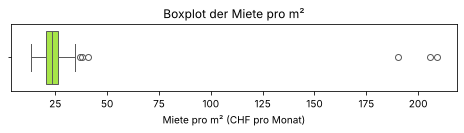

    listing_id         town  rooms  area_m2  rent_chf  rent_per_m2
2     WM-20003  Biel/Bienne    3.5     89.0   18600.0   208.988764
20    WM-20021  Biel/Bienne    2.5     70.0   14400.0   205.714286
15    WM-20016   St. Gallen    5.5    133.0   25320.0   190.375940
141   WM-20142       Zürich    2.5     61.0    2500.0    40.983607 



town
Zürich          32.22
Luzern          24.82
Basel           24.76
Winterthur      23.56
Bern            22.36
St. Gallen      18.26
Schaffhausen    17.24
Biel/Bienne     16.33
Name: rent_per_m2, dtype: float64

In [5]:
# Select columns for the analysis
df_B2 = df_clean[['listing_id', 'town', 'rooms', 'area_m2', 'rent_chf']]

# Rent per m2
df_B2['rent_per_m2'] = df_B2['rent_chf'] / df_B2['area_m2']

# EDA: statistical measures, boxplot and the highest values
print(df_B2['rent_per_m2'].describe().round(2), '\n')
plt.figure(figsize=(8, 1.2))
sns.boxplot(x=df_B2['rent_per_m2'], color='greenyellow')
plt.title('Boxplot der Miete pro m²', fontsize=12)
plt.xlabel('Miete pro m² (CHF pro Monat)')
plt.show()
print(df_B2.sort_values(by='rent_per_m2', ascending=False).head(4), '\n')

# Correct the data entry errors: annual instead of monthly rent (more than CHF 100 per m2)
annual = df_B2['rent_per_m2'] > 100
df_B2.loc[annual, 'rent_chf'] = df_B2.loc[annual, 'rent_chf'] / 12
df_B2['rent_per_m2'] = df_B2['rent_chf'] / df_B2['area_m2']

# Mean rent per m2 per town
df_B2.groupby('town')['rent_per_m2'].mean().round(2).sort_values(ascending=False)

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bewertung: Entscheidend ist, dass die Erfassungsfehler erkannt und begründet behandelt werden. Korrigieren (÷ 12) und Entfernen gelten beide als korrekt; ebenso Mittelwert oder Median nach der Behandlung. Nur auf den Median auszuweichen, ohne die Fehler zu behandeln, ist unvollständig.*
>
> *Bezug: Folien Woche 4 Teil II, S. 13 (Outliers & Measurement Errors); Folien Woche 5, S. 18–19 (Schiefe) und S. 29–30 (Box plot); AP02 B2.*

---
## Teil C – Python-Code schreiben (12 Punkte)

Schreiben Sie Python-Code und begründen Sie Ihre Vorgehensweise jeweils in 1–2 Sätzen. Worauf die Begründung eingehen soll, steht bei der Aufgabe.

### C1 (4 Punkte)

Die Datei `html/listing_detail.html` enthält die Detailseite eines Inserats in Winterthur. In der Code-Zelle ist ein Gerüst vorgegeben, das die HTML-Datei einliest und eine Tabelle Zeile für Zeile in den Data Frame `df_C1` mit den Spalten `merkmal` und `wert` überführt.

Ergänzen Sie die drei mit `# TODO` markierten Stellen:

1. Wählen Sie die Tabelle **«Objektdaten»** aus.
2. Lesen Sie pro Zeile den Merkmalsnamen und den Wert aus. **Achtung:** In dieser Tabelle steht der Merkmalsname in einer `<th>`-Zelle, der Wert in einer `<td>`-Zelle.
3. Entfernen Sie die Gruppenüberschriften (z.B. «Lage») — sie sind **keine** Merkmale.

Begründen Sie, wie Sie die richtige Tabelle auswählen und wie Sie die Gruppenüberschriften erkennen.

*Tipp: Öffnen Sie die HTML-Datei im Editor.*

**Begründung der Vorgehensweise:**

Die Seite enthält zwei Tabellen («Kosten» und «Objektdaten»). Die Tabelle «Objektdaten» hat das Attribut `id="object-data"` und lässt sich damit eindeutig auswählen (`soup.find('table', id='object-data')`; alternativ `find_all('table')[1]`). Gruppenüberschriften bestehen nur aus einer `<th colspan="2">`-Zelle **ohne** `<td>` — für sie wird `wert = None` gesetzt, und `dropna()` entfernt diese Zeilen.

Ergebnis: 10 Merkmale (Adresse, Stockwerk, Zimmer, Wohnfläche, Baujahr, Bezug, Balkon, Lift, Waschturm in Wohnung, Haustiere erlaubt).

**Python-Code:**

In [6]:
# Read html from file
with open('html/listing_detail.html', 'r', encoding='utf-8') as file:
    html_content = file.read()

# Parse the HTML content
soup = BeautifulSoup(html_content, 'html.parser')

# Locate the table «Objektdaten» (via its id; alternatively soup.find_all('table')[1])
table = soup.find('table', id='object-data')

# Extract table rows
rows = []
for row in table.find_all('tr'):

    # Extract the feature name (<th>) and the value (<td>) of the row
    merkmal = row.find('th').get_text().strip()
    wert = row.find('td').get_text().strip() if row.find('td') is not None else None

    rows.append([merkmal, wert])

# Create a DataFrame
df_C1 = pd.DataFrame(rows, columns=['merkmal', 'wert'])

# Remove the group headings (rows without <td>, i.e. without value)
df_C1 = df_C1.dropna().reset_index(drop=True)

# Show the result
df_C1

,merkmal,wert
0,Adresse,"Seestrasse 26, 8400 Winterthur"
1,Stockwerk,3. OG
2,Zimmer,3.5
3,Wohnfläche,106 m²
4,Baujahr,2004
5,Bezug,01.11.2026
6,Balkon,Ja
7,Lift,Ja
8,Waschturm in Wohnung,Ja
9,Haustiere erlaubt,Nein


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Alternative: Gruppenzeilen über ihre Klasse erkennen, z.B. `table.select('tr:not(.group)')` oder `if 'group' in row.get('class', [])`.*
>
> *Bezug: Übung `skipass_data.ipynb` (`find('table')`, `find_all('tr')`, `get_text()`); AP02 C1 (Zwischenüberschriften entfernen mit `dropna()`).*

### C2 (4 Punkte)

Die Datei `municipalities.json` enthält die gespeicherte Antwort der Gemeinde-API. Die Gemeinden stehen **nicht** auf der obersten Ebene, sondern in der Liste unter dem Schlüssel `municipalities` (zusätzlich gibt es den Schlüssel `meta`).

Lesen Sie die Gemeinden in einen Data Frame `df_muni` ein und verbinden Sie ihn mit `.merge()` über die Postleitzahl (`zip`) so mit `df_clean`, dass **alle Inserate** erhalten bleiben. Geben Sie aus, wie viele Inserate **keine** Gemeindedaten erhalten haben, und berechnen Sie pro Kanton (`canton`) die Anzahl Inserate und die Median-Miete (`rent_chf`) — Inserate ohne Kanton sollen dabei als eigene Gruppe sichtbar bleiben.

Begründen Sie Ihre Wahl der Join-Methode und warum Sie beim Gruppieren einen zusätzlichen Parameter benötigen.

**Begründung der Vorgehensweise:**

Die JSON-Datei wird mit `json.load()` als Python-Dictionary eingelesen; `pd.DataFrame(data['municipalities'])` macht aus der Liste unter `municipalities` einen Data Frame (alternativ `pd.json_normalize(data, record_path='municipalities')`). `how='left'` behält alle 180 Inserate, auch wenn eine Postleitzahl in der API fehlt. Das betrifft die **10 Inserate in Schaffhausen** (8200) — sie erhalten `NaN` in `canton`.

`groupby()` lässt Gruppen mit fehlendem Schlüssel standardmässig weg; mit `dropna=False` bleiben die 10 Inserate als Gruppe `NaN` sichtbar. Sonst würde man fälschlich annehmen, alle Inserate seien einem Kanton zugeordnet.

**Python-Code:**

In [7]:
# Read the JSON file (nested structure: 'meta' and 'municipalities')
with open('municipalities.json', 'r', encoding='utf-8') as file:
    data = json.load(file)
print(data.keys(), '\n')

# Data frame of the municipalities
df_muni = pd.DataFrame(data['municipalities'])

# Join the municipality data to the listings (left join: keep all listings)
df_C2 = df_clean.merge(df_muni[['zip', 'canton', 'population', 'tax_multiplier_pct']], on='zip', how='left')
print('Anzahl Inserate:                ', df_C2.shape[0])
print('Inserate ohne Gemeindedaten:    ', df_C2['canton'].isnull().sum())
print(df_C2.loc[df_C2['canton'].isnull(), 'town'].unique(), '\n')

# Number of listings and median rent per canton (keep listings without canton as own group)
df_C2.groupby('canton', dropna=False)['rent_chf'].agg(['size', 'median'])

dict_keys(['meta', 'municipalities']) 

Anzahl Inserate:                 180
Inserate ohne Gemeindedaten:     10
<StringArray>
['Schaffhausen']
Length: 1, dtype: str 



,size,median
canton,,
BE,47,1660.0
BS,33,2060.0
LU,21,2245.0
SG,18,1420.0
ZH,51,2330.0
NaN,10,1305.0


> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Bezug: Folien Woche 4 Teil I, S. 37 (JSON) und S. 66–71 (REST-APIs, HTTP-Response); Übung `input_output_and_formatting_Python.ipynb` (JSON lesen); Folien Woche 4 Teil II, S. 41–44 (`.merge()`) und S. 49–50 (`.groupby()`).*

### C3 (4 Punkte)

Erstellen Sie mit `pd.pivot_table()` eine Tabelle mit der **Median-Miete** (`rent_chf`) pro Ort (`town`, Zeilen) und Zimmerzahl (`rooms`, Spalten) auf Basis von `df_clean`. Stellen Sie die Tabelle als **Heatmap** mit `sns.heatmap()` dar (Werte in den Zellen anzeigen, Titel und Achsenbeschriftungen).

Begründen Sie, warum hier der Median verwendet wird, und erklären Sie die beiden auffälligen Zellen für **Schaffhausen / 5.5 Zimmer** und **St. Gallen / 5.5 Zimmer**.

**Begründung der Vorgehensweise:**

`pd.pivot_table(..., index='town', columns='rooms', aggfunc='median')` aggregiert die Mieten pro Kombination aus Ort und Zimmerzahl. Der **Median** ist robuster gegenüber Ausreissern bzw. Erfassungsfehlern als der Mittelwert (Mieten sind rechtsschief, vgl. A2).

Auffällige Zellen: **Schaffhausen / 5.5** ist leer (`NaN`) — es gibt dort kein 5.5-Zimmer-Inserat. **St. Gallen / 5.5** zeigt CHF 13'855: Die Zelle beruht auf nur **zwei** Inseraten, eines davon mit der Jahresmiete von CHF 25'320 (vgl. A2/B2). Bei nur zwei Werten ist der Median der Mittelwert beider Werte — auch der Median ist bei so kleinen Gruppen **nicht** robust. Vor der Interpretation müssten die Erfassungsfehler korrigiert werden.

**Python-Code:**

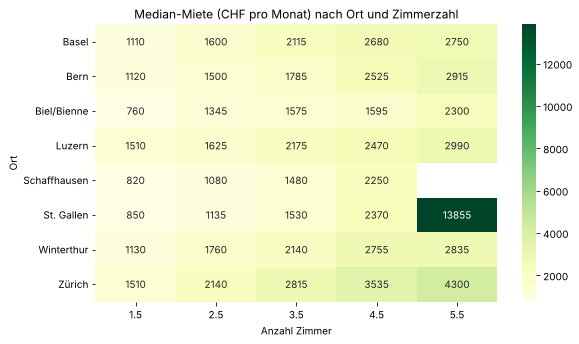

rooms,1.5,2.5,3.5,4.5,5.5
town,,,,,
Basel,4,10,10,8,1
Bern,3,11,10,4,2
Biel/Bienne,1,4,9,2,1
Luzern,1,3,12,4,1
Schaffhausen,1,3,4,2,0
St. Gallen,2,6,6,2,2
Winterthur,2,3,9,2,4
Zürich,2,15,6,5,3


In [8]:
# Median rent per town and number of rooms
df_C3 = pd.pivot_table(df_clean, values='rent_chf', index='town', columns='rooms', aggfunc='median')

# Heatmap of the pivot table
plt.figure(figsize=(9, 5))
sns.heatmap(df_C3, annot=True, fmt='.0f', cmap='YlGn')
plt.title('Median-Miete (CHF pro Monat) nach Ort und Zimmerzahl', fontsize=12)
plt.xlabel('Anzahl Zimmer')
plt.ylabel('Ort')
plt.show()

# Number of listings per cell (to check the cells)
pd.crosstab(df_clean['town'], df_clean['rooms'])

> **Nicht Teil der Antwort** — Bezug zu Folien bzw. Übungen
>
> *Hinweis: Die Kontrolltabelle mit `pd.crosstab()` ist nicht verlangt, zeigt aber, wie viele Inserate hinter jeder Zelle stehen.*
>
> *Bezug: Folien Woche 4 Teil II, S. 55–56 (`.pivot_table()`); Folien Woche 5, S. 21–22 (Kontingenztabelle), S. 41 (Heat map) und S. 45 (Seaborn).*

---
### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [9]:
# Libraries
import os, platform, socket
from platform import python_version
from datetime import datetime

# Print system information
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('IP Address:', socket.gethostbyname(socket.gethostname()))
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.18.44-fc-v310
Datetime: 2026-11-07 10:51:44
Python Version: 3.13.18
IP Address: 127.0.0.1
-----------------------------------
